# NX-421 Mini-project 2 — Part 1: single-subject classification
**Variant 3 → Gradient boosting** · NinaPro DB1, exercise 1 (12 actions)

Layout: **0 Config** (edit) → **1 Imports & helpers** (reused in Part 2) → **Q1–Q6**.
Every section is marked with `# ===== ... =====` so you can find it quickly.

In [1]:
# =====================================================================
# 0. CONFIG
# =====================================================================

SUBJECT = 2   
DATA_PATH_TEMPLATE = f"data/s{SUBJECT}/S{SUBJECT}_A1_E1.mat" 
                                             

EMG_KEY   = "emg"           # (n_samples, 10) EMG
LABEL_KEY = "restimulus"    # movement label, refined by NinaPro (0 = rest, 1..12 = action)
REP_KEY   = "rerepetition"  # repetition index (1..10), refined by NinaPro


FS        = 100   # Hz, DB1 sampling rate
N_ACTIONS = 12
N_REPS    = 10

SEED = 42

# ---- Preprocessing (Q1) ----------------------------------------------------
LOWPASS_HZ    = None   # e.g. 20 to low-pass filter; None = off (DB1 is already a smoothed envelope)
MIN_LEN_FRAC  = 0.5    # QC: drop trial if shorter than this fraction of the median length of its action
AMP_OUTLIER_K = 5.0    # QC: drop trial if a channel's peak > K x that channel's median trial peak
PLOT_SECONDS  = 60     # length of raw-signal plot
EXAMPLE_REP   = 1      # repetition shown in the "one trial per action" plot


# ---- Split by repetition (Q2): every action has one trial per repetition ----
TRAIN_REPS = [1, 3, 4, 6, 7, 8]
VAL_REPS   = [9, 10]
TEST_REPS  = [2, 5]

# ---- Features (Q3) ------------------------------------------------------------
THR_FRAC     = 0.1     # threshold for ZC / SSC / WAMP = THR_FRAC x std of the segment (per channel)
VIS_ACTION   = 1       # action used in the repetition-vs-repetition plot


In [2]:
# =====================================================================
# 1a. IMPORTS
# =====================================================================
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.signal import butter, filtfilt
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import (accuracy_score, f1_score)



warnings.filterwarnings("ignore", category=RuntimeWarning)  # constant-feature warnings
np.random.seed(SEED)

In [3]:
# =====================================================================
# 1b. HELPERS: loading, preprocessing, segmentation, QC
# =====================================================================
def load_subject(subj):
    """Load one NinaPro DB1 .mat file -> (emg [T,C], labels [T], reps [T])."""
    m = loadmat(DATA_PATH_TEMPLATE.format(subj=subj))
    return (m[EMG_KEY].astype(float),
            m[LABEL_KEY].ravel().astype(int),
            m[REP_KEY].ravel().astype(int))


def preprocess_emg(emg, lowpass_hz=None, fs=FS):
    """Interpolate NaNs, optional zero-phase Butterworth low-pass (per channel)."""
    emg = pd.DataFrame(emg).interpolate(limit_direction="both").to_numpy()
    if lowpass_hz:
        b, a = butter(4, lowpass_hz / (fs / 2))
        emg = filtfilt(b, a, emg, axis=0)
    return emg


def get_trials(emg, labels, reps):
    """Cut the recording into trials: one per (action, repetition), rest (label 0) excluded."""
    trials = []
    for a in range(1, N_ACTIONS + 1):
        for r in range(1, N_REPS + 1):
            mask = (labels == a) & (reps == r)
            if mask.any():
                trials.append(dict(action=a, rep=r, data=emg[mask]))
    return trials


def qc_trials(trials, min_len_frac=MIN_LEN_FRAC, amp_k=AMP_OUTLIER_K):
    """Flag bad trials (too short / amplitude spike / NaN). Returns (kept_trials, qc_table)."""
    df = pd.DataFrame({"action": [t["action"] for t in trials],
                       "rep":    [t["rep"] for t in trials],
                       "n":      [len(t["data"]) for t in trials]})
    peak = np.array([np.nanmax(t["data"], axis=0) for t in trials])           # (trials, C)
    df["short"] = df["n"] < min_len_frac * df.groupby("action")["n"].transform("median")
    df["spike"] = (peak / (np.median(peak, axis=0) + 1e-12)).max(axis=1) > amp_k
    df["nan"]   = [bool(np.isnan(t["data"]).any()) for t in trials]
    df["bad"]   = df[["short", "spike", "nan"]].any(axis=1)
    kept = [t for t, b in zip(trials, df["bad"]) if not b]
    return kept, df

In [4]:
# =====================================================================
# 1c. FEATURES  (each takes a segment [T, C] and returns one value per channel [C])
# =====================================================================
def _thr(x):                       # per-channel adaptive threshold
    return THR_FRAC * x.std(axis=0)

def f_mav(x):  return np.mean(np.abs(x), axis=0)                    # Mean absolute value
def f_rms(x):  return np.sqrt(np.mean(x ** 2, axis=0))              # Root mean square
def f_wl(x):   return np.sum(np.abs(np.diff(x, axis=0)), axis=0)    # Waveform length
def f_max(x):  return np.max(np.abs(x), axis=0)                     # Peak amplitude

def f_zc(x):                                                        # (Mean-)crossing count
    x = x - x.mean(axis=0)                                          # signal is rectified -> cross the mean
    return np.sum((x[:-1] * x[1:] < 0) & (np.abs(x[:-1] - x[1:]) >= _thr(x)), axis=0)

def f_ssc(x):                                                       # Slope sign changes
    d1, d2 = x[1:-1] - x[:-2], x[1:-1] - x[2:]
    return np.sum((d1 * d2 > 0) & ((np.abs(d1) >= _thr(x)) | (np.abs(d2) >= _thr(x))), axis=0)

def f_wamp(x):                                                      # Willison amplitude
    return np.sum(np.abs(np.diff(x, axis=0)) >= _thr(x), axis=0)

FEATURES = {"MAV": f_mav, "RMS": f_rms, "WL": f_wl, "MAX": f_max,
            "ZC": f_zc, "SSC": f_ssc, "WAMP": f_wamp}


def windows(x, win_len=None, step=None):
    """Split a segment into windows; win_len=None -> the whole segment is one window."""
    if win_len is None:
        return [x]
    step = step or win_len
    return [x[i:i + win_len] for i in range(0, len(x) - win_len + 1, step)]


def trials_to_features(trials, feats=FEATURES):
    """Trials -> X [n, n_feat*C] (feature-major order), y [n], rep [n], feature names."""
    X, y, rep = [], [], []
    for t in trials:
        for w in windows(t["data"]):
            X.append(np.concatenate([f(w) for f in feats.values()]))
            y.append(t["action"]); rep.append(t["rep"])
    C = trials[0]["data"].shape[1]
    names = [f"{fn}_ch{c + 1}" for fn in feats for c in range(C)]
    return np.array(X), np.array(y), np.array(rep), names


def build_dataset(subj, verbose=False):
    """Full pipeline for one subject (use this in Part 2): load -> preprocess -> trials -> QC -> features."""
    emg, lab, rep = load_subject(subj)
    emg = preprocess_emg(emg, LOWPASS_HZ)
    trials, qc = qc_trials(get_trials(emg, lab, rep))
    if verbose:
        print(f"Subject {subj}: kept {len(trials)}/{len(qc)} trials")
    return trials_to_features(trials)

In [5]:
# =====================================================================
# 1d. HELPERS: split, model, hyper-parameter tuning, evaluation
# =====================================================================
def split_by_rep(rep, train=TRAIN_REPS, val=VAL_REPS, test=TEST_REPS):
    """Boolean masks for train / val / test, split by repetition (no leakage between sets)."""
    return np.isin(rep, train), np.isin(rep, val), np.isin(rep, test)


def make_clf(**params):
    """Classifier (variant 3). For many windows, swap to HistGradientBoostingClassifier (faster)."""
    return GradientBoostingClassifier(random_state=SEED, max_features="sqrt", **params)


def tune_on_validation(estimator, grid, Xtr, ytr, Xva, yva):
    """Grid search: fit on train, score (accuracy) on validation. Works for models and Pipelines."""
    plist = list(ParameterGrid(grid))
    scores = [accuracy_score(yva, clone(estimator).set_params(**p).fit(Xtr, ytr).predict(Xva))
              for p in plist]
    table = pd.DataFrame(plist).assign(val_acc=scores).sort_values("val_acc", ascending=False)
    return plist[int(np.argmax(scores))], table


def refit_and_test(estimator, params, Xtr, ytr, Xva, yva, Xte, yte):
    """Refit with best params on train+val, evaluate once on test. Returns (model, pred, scores)."""
    m = clone(estimator).set_params(**params).fit(np.vstack([Xtr, Xva]), np.r_[ytr, yva])
    pred = m.predict(Xte)
    return m, pred, {"accuracy": accuracy_score(yte, pred),
                     "macro_F1": f1_score(yte, pred, average="macro")}

---
# Q1 — Visualise & preprocess

In [6]:
# ===== Q1.1 Load + preprocess ========================================
emg_raw, labels, reps = load_subject(SUBJECT)
print("EMG shape:", emg_raw.shape, "| NaNs:", int(np.isnan(emg_raw).sum()))
print("Labels:", np.unique(labels), "| Repetitions:", np.unique(reps))
emg = preprocess_emg(emg_raw, LOWPASS_HZ)

EMG shape: (100686, 10) | NaNs: 0
Labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12] | Repetitions: [ 0  1  2  3  4  5  6  7  8  9 10]


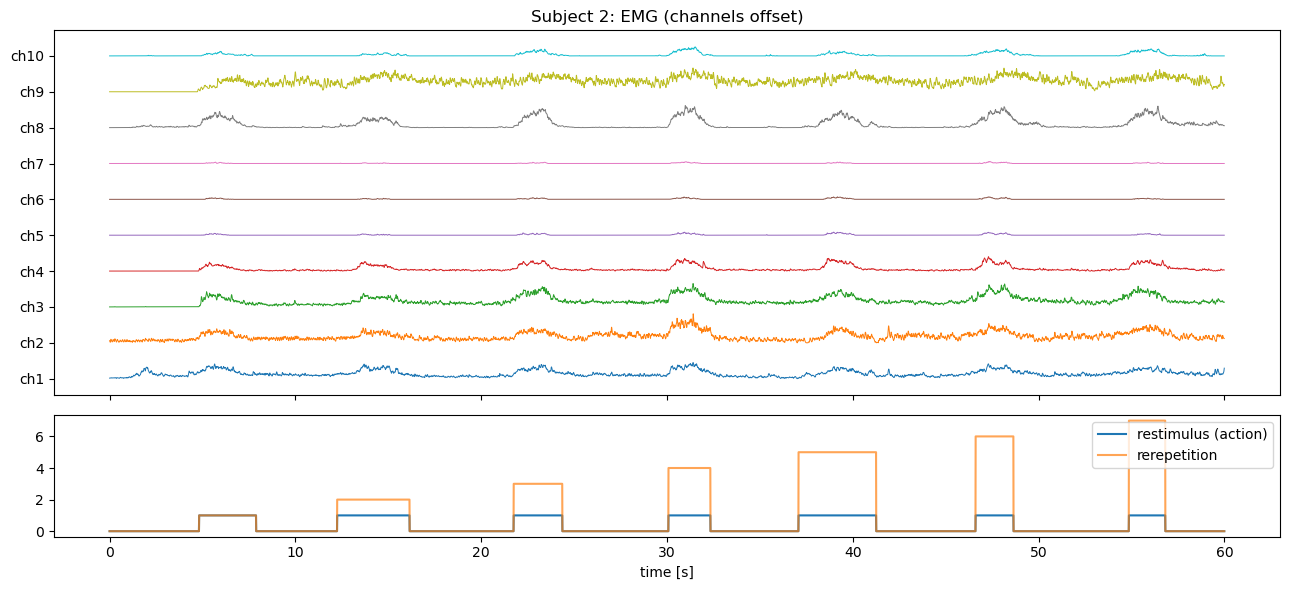

In [7]:
# ===== Q1.2 Plot raw signal (all channels) + stimulus/repetition ============
n = int(PLOT_SECONDS * FS); t = np.arange(n) / FS
off = np.percentile(emg, 99.5)
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
for c in range(emg.shape[1]):
    ax[0].plot(t, emg[:n, c] + c * off, lw=0.7)
ax[0].set_yticks(np.arange(emg.shape[1]) * off); ax[0].set_yticklabels([f"ch{c+1}" for c in range(emg.shape[1])])
ax[0].set_title(f"Subject {SUBJECT}: EMG (channels offset)")
ax[1].plot(t, labels[:n], label="restimulus (action)"); ax[1].plot(t, reps[:n], label="rerepetition", alpha=.7)
ax[1].set_xlabel("time [s]"); ax[1].legend(loc="upper right")
plt.tight_layout()
plt.savefig(f"figures/fig1_subject_{SUBJECT}_raw_emg.png", dpi=300)
plt.show()

Trials found: 120 (expected 120) | kept: 118
Flagged trials:
      action  rep    n  short  spike    nan   bad
87        9    8  284  False   True  False  True
113      12    4  387  False   True  False  True


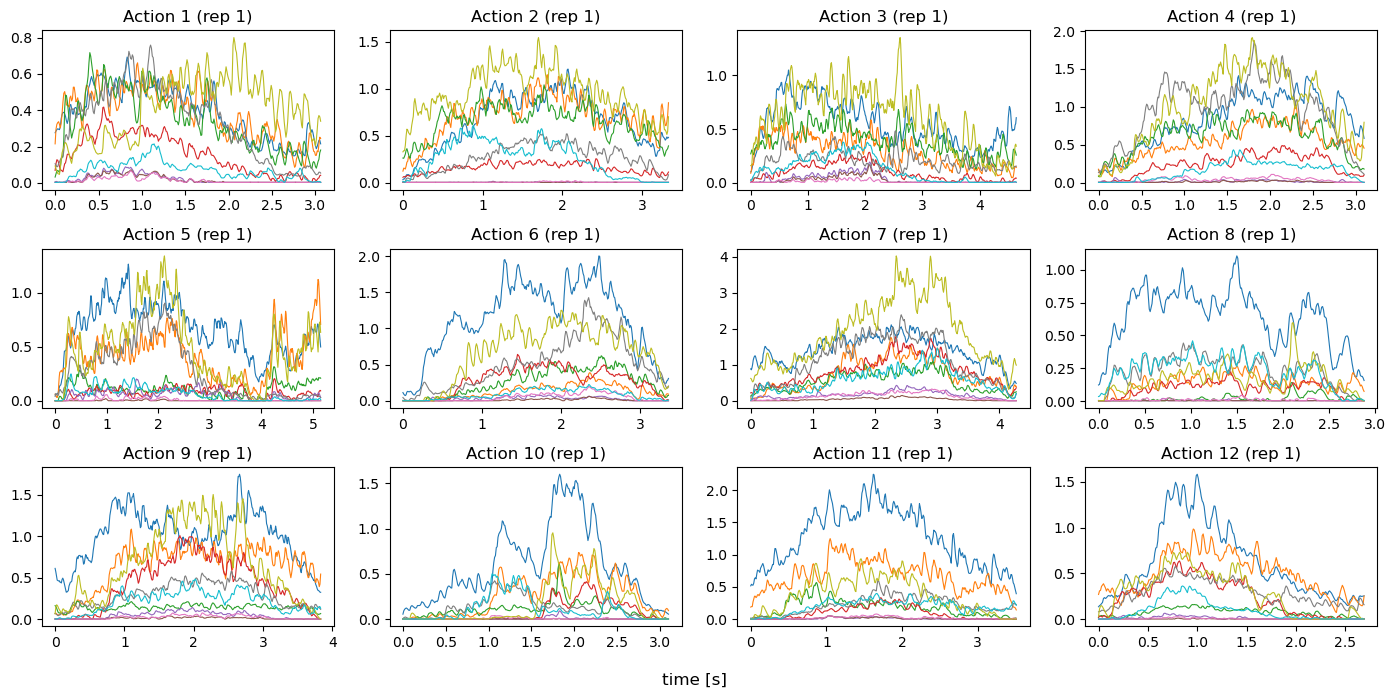

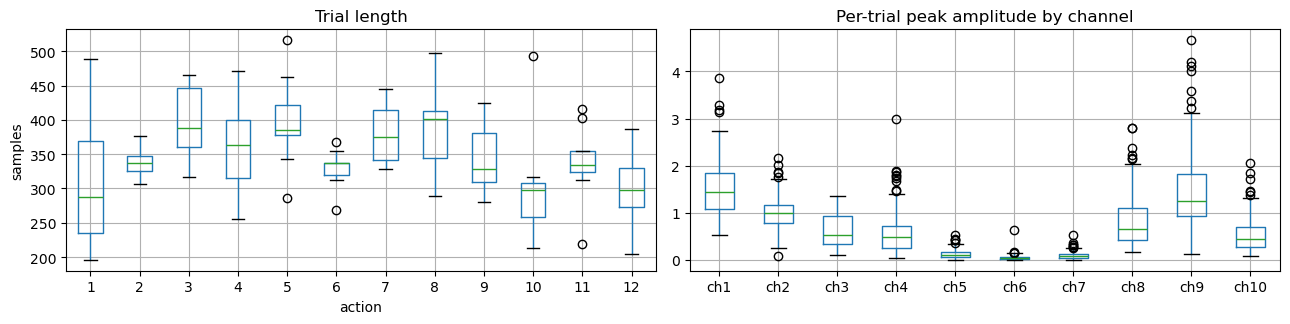

In [8]:
# ===== Q1.3 Cut trials, Quality Control, and show one trial per action ====================
trials_all = get_trials(emg, labels, reps)
trials, qc = qc_trials(trials_all)
print(f"Trials found: {len(qc)} (expected {N_ACTIONS * N_REPS}) | kept: {len(trials)}")
print("Flagged trials:\n", qc[qc.bad].to_string() if qc.bad.any() else "none")

fig, axs = plt.subplots(3, 4, figsize=(14, 7), sharex=False)
for a, ax in zip(range(1, N_ACTIONS + 1), axs.ravel()):
    tr = [t_ for t_ in trials_all if t_["action"] == a and t_["rep"] == EXAMPLE_REP]
    if tr: ax.plot(np.arange(len(tr[0]["data"])) / FS, tr[0]["data"], lw=0.8)
    ax.set_title(f"Action {a} (rep {EXAMPLE_REP})")
fig.supxlabel("time [s]"); plt.tight_layout(); plt.show()

# Trial duration per action + per-channel peak amplitude
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
qc.boxplot(column="n", by="action", ax=ax[0]); ax[0].set_ylabel("samples"); ax[0].set_title("Trial length")
pd.DataFrame(np.array([t_["data"].max(0) for t_ in trials_all]),
             columns=[f"ch{c+1}" for c in range(emg.shape[1])]).boxplot(ax=ax[1])
ax[1].set_title("Per-trial peak amplitude by channel"); plt.suptitle(""); plt.tight_layout(); plt.show()

**Data**: 10 channels at 100 Hz sampling rate. DB1 signals are already rectified and smoothed (Otto Bock electrodes: analog filtering + smoothing), so no band-pass or notch filter is applied. Only smooth bursts, with no 50 Hz (mains) ripple. 

data quality: channels 5–7 are almost silent (peak ≈ 0.1, against 1–4 for the others), and ch9 has a noisier baseline. Each trial is a bell-shaped burst of about 2–5 s.

**Preprocessing**: NaN interpolation (none found), segmentation into 120 trials (12 actions × 10 repetitions, restimulus / rerepetition), and automatic QC.

**Reasonable?** Yes. Activity is clearly visible during each movement and returns to baseline at rest; each trial is a smooth bell-shaped burst lasting about 2–5 s. Points to note:
Channels 5–7 are almost silent (peak ≈ 0.1 vs 1–4 for the others).
Channels 1 and 9 have the largest amplitudes, and ch9 has a noisier baseline.
Trial duration varies a lot within an action (e.g. action 1: ~200–490 samples).
Removed trials: 2 of 120, both flagged for an amplitude spike: (action 9, rep 8) and (action 12, rep 4). 118 trials remain.

Each action produces a bell-shaped activation with a characteristic distribution across channels (ch1, 2, 8, 9 dominant; ch5–7 near silent), and trial durations differ between actions

---
# Q2 — Train / validation / test split

In [9]:
# ===== Q2 Split by repetition ================================================
# Features are computed per trial, so we split BY REPETITION: neighbouring windows of the same
# repetition never end up in different sets.
X, y, rep, feat_names = trials_to_features(trials)      # (also used in Q3)
tr, va, te = split_by_rep(rep)
Xtr, ytr, Xva, yva, Xte, yte = X[tr], y[tr], X[va], y[va], X[te], y[te]
print(f"X: {X.shape}: \n train {tr.sum()} \n val {va.sum()} \n test {te.sum()}")
print("Samples per action  train:", np.bincount(ytr)[1:], " val:", np.bincount(yva)[1:], " test:", np.bincount(yte)[1:])

X: (118, 70): 
 train 70 
 val 24 
 test 24
Samples per action  train: [6 6 6 6 6 6 6 6 5 6 6 5]  val: [2 2 2 2 2 2 2 2 2 2 2 2]  test: [2 2 2 2 2 2 2 2 2 2 2 2]


Split by repetition: train reps 1,3,4,6,7,8 (70 trials, since both removed trials are in the train reps); validation reps 9,10 (24); test reps 2,5 (24). Actions 9 and 12 have 5 train trials instead of 6.

Why three sets: 
- train = fit the model; 
- validation = choose hyperparameters / feature selection without touching the test set; 
- test = one final, unbiased estimate of generalisation. Reusing a set for tuning and for the final score gives an optimistic result.

---
# Q3 — Features

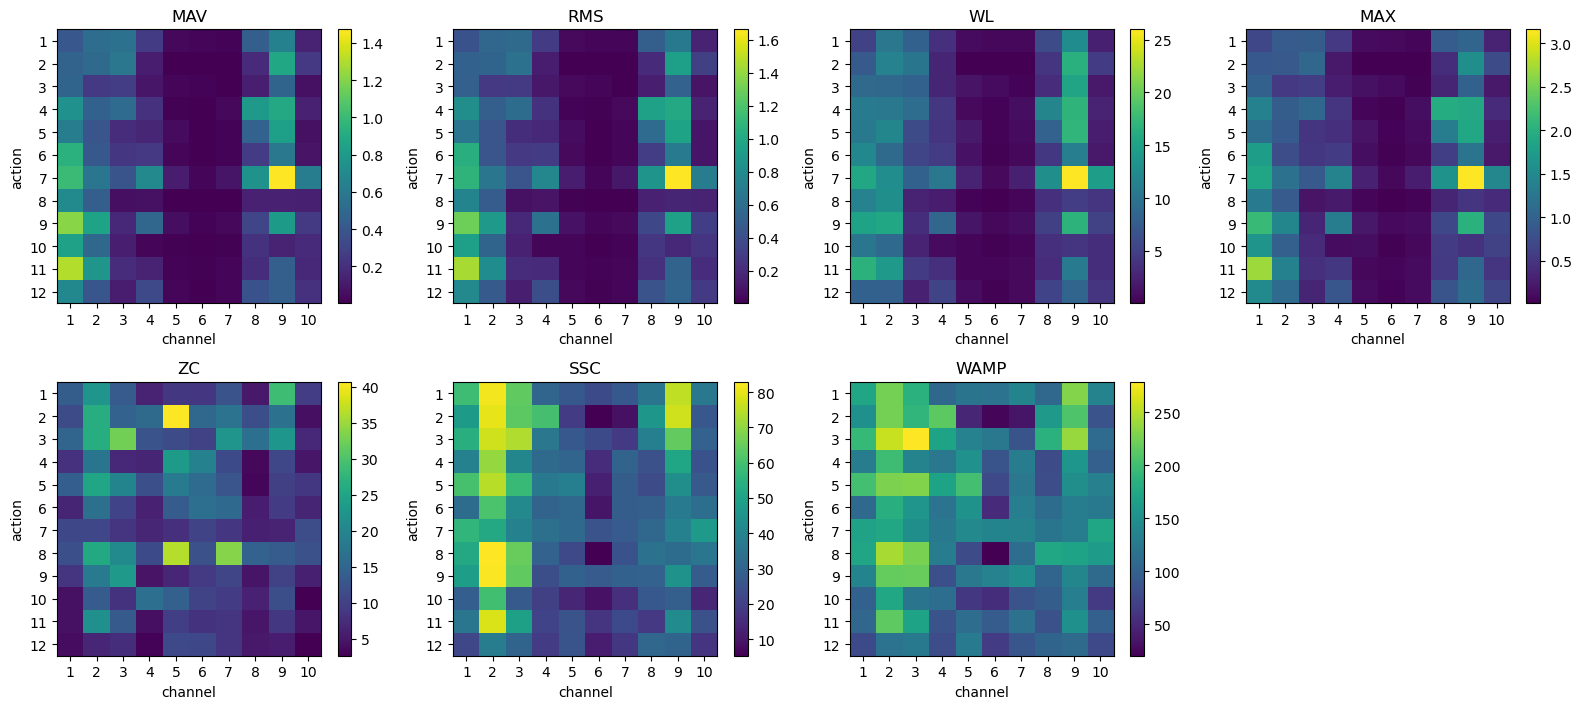

In [10]:
# ===== Q3.1 Heatmaps: mean feature value per action x channel ==================
X3 = X.reshape(len(X), len(FEATURES), -1)                # (trials, feature, channel)
n_f = len(FEATURES); n_cols = 4; n_rows = int(np.ceil(n_f / n_cols))
fig, axs = plt.subplots(n_rows, n_cols, figsize=(16, 3.6 * n_rows))
for i, (fn, ax) in enumerate(zip(FEATURES, axs.ravel())):
    M = np.array([X3[y == a, i].mean(0) for a in range(1, N_ACTIONS + 1)])
    im = ax.imshow(M, aspect="auto"); plt.colorbar(im, ax=ax)
    ax.set_title(fn); ax.set_xlabel("channel"); ax.set_ylabel("action")
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(range(1, M.shape[1] + 1))
    ax.set_yticks(range(N_ACTIONS)); ax.set_yticklabels(range(1, N_ACTIONS + 1))
for ax in axs.ravel()[n_f:]: ax.axis("off")
plt.tight_layout(); plt.show()

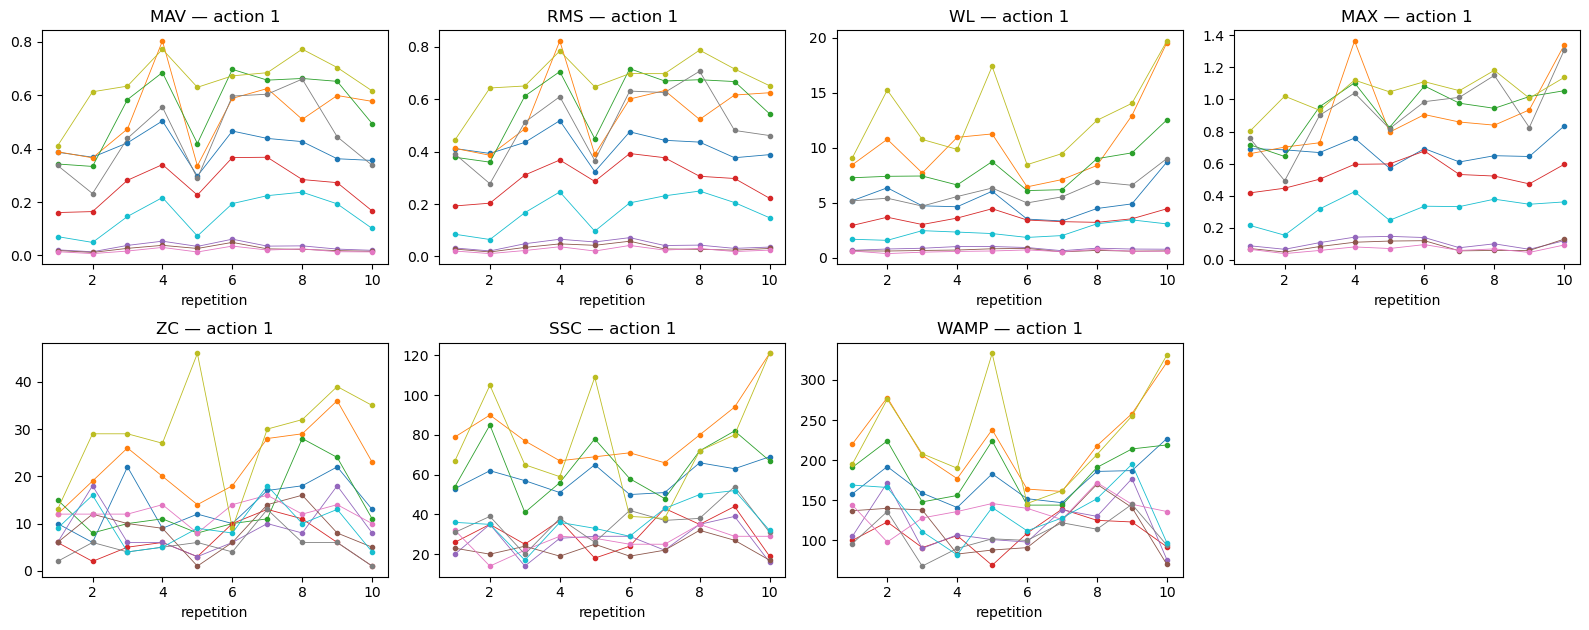

Mean CV across repetitions:
 MAV     0.343
RMS     0.338
WL      0.305
MAX     0.336
ZC      0.524
SSC     0.321
WAMP    0.278


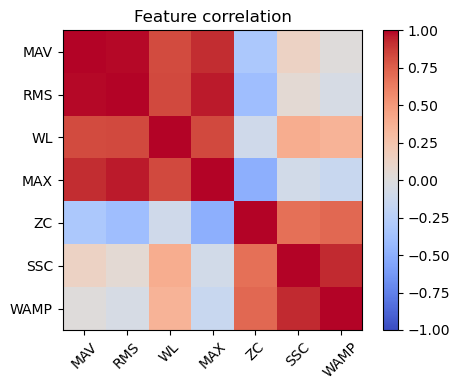

In [11]:
# ===== Q3.2 Repetition-to-repetition variability ===============================
# (a) one action, value of each feature across repetitions (one line per channel)
fig, axs = plt.subplots(n_rows, n_cols, figsize=(16, 3.2 * n_rows))
m = y == VIS_ACTION
for i, (fn, ax) in enumerate(zip(FEATURES, axs.ravel())):
    ax.plot(rep[m], X3[m, i], "o-", lw=0.6, ms=3); ax.set_title(f"{fn} — action {VIS_ACTION}")
    ax.set_xlabel("repetition")
for ax in axs.ravel()[n_f:]: ax.axis("off")
plt.tight_layout(); plt.show()

# (b) coefficient of variation across repetitions (lower = more repeatable)
cv = {fn: np.mean([X3[y == a, i].std(0) / (X3[y == a, i].mean(0) + 1e-12)
                   for a in range(1, N_ACTIONS + 1)]) for i, fn in enumerate(FEATURES)}
print("Mean CV across repetitions:\n", pd.Series(cv).round(3).to_string())

# (c) correlation between features (all channels) — shows redundant features
plt.figure(figsize=(5, 4)); C_ = np.corrcoef(X3.mean(2).T)          # channel-averaged feature values
plt.imshow(C_, vmin=-1, vmax=1, cmap="coolwarm"); plt.colorbar()
plt.xticks(range(n_f), FEATURES, rotation=45); plt.yticks(range(n_f), FEATURES)
plt.title("Feature correlation"); plt.tight_layout(); plt.show()

**7 features Chosen**:

- MAV (mean absolute value), RMS (root mean square), MAX (maximal value): amplitude / activation level.
- WL (waveform length): signal complexity and amplitude.
- ZC (mean crossings), SSC (slope sign changes), WAMP (willison amplitude): frequency/complexity content. The signal is rectified, so ZC is computed around the mean.

**Observations**:

- MAV/RMS/MAX/WL show the same spatial pattern: ch1, 2, 8, 9 dominate and ch5–7 are ≈ 0 for every action. Each action has its own channel "fingerprint" (e.g. action 7 is strong on ch9, ch1, ch8; actions 9 and 11 on ch1–2). These four features are strongly correlated (MAV–RMS ≈ 1, MAV–MAX ≈ 0.9, MAV–WL ≈ 0.7), so they are partly redundant.

- ZC/SSC/WAMP have a different spatial pattern (highest on ch2–3 and ch9) and are only weakly or negatively correlated with amplitude (SSC–WAMP ≈ 0.9). They carry complementary information but are noisier (ZC has the highest CV).

- Between repetitions: similar but not identical (CV across repetitions ≈ 0.28 (WAMP) to 0.52 (ZC)). For action 1 the amplitude features go up and down together across all channels from one repetition to the next, while the channel ordering stays the same. So the variation comes mainly from effort, speed and timing (plus fatigue), not from the electrodes. WL, ZC, SSC and WAMP are un-normalised counts/sums, so they also grow with trial duration (2–5 s), which adds spurious variability.

- Between channels: large differences. Reasons: electrode position relative to the active muscles (ch9/ch10 sit over the flexor/extensor digitorum, ch1–8 are spread around the forearm), skin/fat thickness, and each action recruiting different muscles. Channels 5–7 probably sit over muscles that are rarely active in these finger movements.